# Лабораторная работа №4. Сравнение полиномиальной и сплайн-интерполяции

Исследуем функцию Рунге

$$f(x)=\frac{1}{1+25x^2},\qquad x\in[-1,1].$$

Нужно проверить, как выбор узлов и способ построения интерполянта влияют на точность:
полиномы в формах Лагранжа и Ньютона на равномерных и вложенных сетках Чебышёва
и кубический сплайн с закреплёнными граничными условиями на тех же сетках.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Функция Рунге: гладкая, но с крутыми «skirts» у краёв отрезка
def f(x):
    return 1.0 / (1.0 + 25.0 * x**2)

# Её производная нужна для закреплённых граничных условий сплайна:
# f'(x) = -50x / (1+25x^2)^2, откуда f'(-1) = 50/676, f'(1) = -50/676
def f_prime(x):
    return -50.0 * x / (1.0 + 25.0 * x**2)**2

### 2. Сетки

Равномерная сетка из условия: $x_j^{(n)} = -1 + 2j/n$, $j=0,\dots,n$ (всего $n+1$ узлов).

Для «сетки Чебышёва» берём **узлы Лобатто** (экстремумы многочлена Чебышёва)
$x_k = \cos(k\pi/n)$, $k=0,\dots,n$: только они вложены при удвоении $n$.
Корневые узлы $\cos\frac{(2k+1)\pi}{2(n+1)}$ вложенность не дают, а условие задачи её требует.
Проверим вложенность явно.

In [2]:
def uniform_grid(n):
    """Равномерная сетка: n+1 узел на [-1, 1]."""
    j = np.arange(n + 1)
    return -1.0 + 2.0 * j / n

def chebyshev_grid(n):
    """Вложенная сетка Чебышёва (узлы Лобатто), отсортированная по возрастанию."""
    k = np.arange(n + 1)
    return np.sort(np.cos(k * np.pi / n))

def is_nested(x_old, x_new, tol=1e-12):
    """Каждый узел старой сетки должен совпасть с узлом новой."""
    return all(np.min(np.abs(x_new - xi)) < tol for xi in x_old)

ns = [4, 8, 16, 32, 64]
for name, grid in [('равномерная', uniform_grid), ('чебышёвская', chebyshev_grid)]:
    ok = all(is_nested(grid(n), grid(2 * n)) for n in ns[:-1])
    print(f'сетка {name} вложена: {ok}')

сетка равномерная вложена: True
сетка чебышёвская вложена: True


### 3. Форма Лагранжа

$$P_n(x)=\sum_{i=0}^{n} f_i L_i(x),\qquad
L_i(x)=\prod_{j\ne i}\frac{x-x_j}{x_i-x_j}.$$

Считаем «в лоб», без готовых функций интерполяции.

In [3]:
def lagrange_interp(nodes, values, x):
    """Значение полинома Лагранжа в точках x (массив)."""
    x = np.asarray(x, dtype=float)
    result = np.zeros_like(x)
    for i in range(len(nodes)):
        Li = np.ones_like(x)
        for j in range(len(nodes)):
            if j != i:
                Li = Li * (x - nodes[j]) / (nodes[i] - nodes[j])
        result = result + values[i] * Li
    return result

### 4. Форма Ньютона

$$P_n(x)=c_0+c_1(x-x_0)+\dots+c_n(x-x_0)\dots(x-x_{n-1}),$$
где $c_k=f[x_0,\dots,x_k]$ — разделённые разности. Таблица строится на месте,
значение считается вложенной схемой Горнера. Обе формы задают **один и тот же**
интерполяционный полином, поэтому их расхождение — мера чисто вычислительной ошибки.

In [4]:
def divided_differences(nodes, values):
    """Коэффициенты Ньютона c[k] = f[x_0,...,x_k] таблицей разделённых разностей."""
    c = np.array(values, dtype=float)
    n = len(c)
    for k in range(1, n):
        for i in range(n - 1, k - 1, -1):
            c[i] = (c[i] - c[i - 1]) / (nodes[i] - nodes[i - k])
    return c

def newton_interp(nodes, coeffs, x):
    """Вложенная схема: p = c_{n-1}; p = c_k + (x - x_k) * p снизу вверх."""
    x = np.asarray(x, dtype=float)
    n = len(nodes)
    p = np.full_like(x, coeffs[n - 1])
    for k in range(n - 2, -1, -1):
        p = coeffs[k] + (x - nodes[k]) * p
    return p

### 5. Кубический сплайн с закреплёнными граничными условиями

Неизвестные — вторые производные $c_i=S''(x_i)$. Внутри узлов — система из лекции 5:

$$\frac{h_i}{6}c_{i-1}+\frac{h_i+h_{i+1}}{3}c_i+\frac{h_{i+1}}{6}c_{i+1}
=\frac{f_{i+1}-f_i}{h_{i+1}}-\frac{f_i-f_{i-1}}{h_i},$$

а закреплённые условия $S'(x_0)=f'(x_0)$, $S'(x_n)=f'(x_n)$ дают первые и последнее
уравнения. Система трёхдиагональная — решаем **прогонкой из лабы 3**.

In [5]:
def progonka(a, b, c, d):
    """Метод прогонки (тот же, что в лабораторной №3)."""
    n = len(d)
    c_new = np.zeros(n)
    d_new = np.zeros(n)

    c_new[0] = c[0] / b[0]
    d_new[0] = d[0] / b[0]

    for i in range(1, n):
        den = b[i] - a[i] * c_new[i - 1]
        if i < n - 1:
            c_new[i] = c[i] / den
        d_new[i] = (d[i] - a[i] * d_new[i - 1]) / den

    x = np.zeros(n)
    x[-1] = d_new[-1]
    for i in range(n - 2, -1, -1):
        x[i] = d_new[i] - c_new[i] * x[i + 1]
    return x

def clamped_spline_coeffs(nodes, values, dleft, dright):
    """Трёхдиагональная система для c_i = S''(x_i) с закреплёнными концами."""
    n = len(nodes) - 1                 # число отрезков
    h = np.diff(nodes)                 # h[i] = x_{i+1} - x_i
    size = n + 1
    a = np.zeros(size); b = np.zeros(size)
    c = np.zeros(size); d = np.zeros(size)

    # левый конец: S'(x_0) = (f_1-f_0)/h_0 - h_0*(2c_0+c_1)/6 = dleft
    b[0] = h[0] / 3.0
    c[0] = h[0] / 6.0
    d[0] = (values[1] - values[0]) / h[0] - dleft

    # внутренние узлы: непрерывность первой производной
    for i in range(1, n):
        a[i] = h[i - 1] / 6.0
        b[i] = (h[i - 1] + h[i]) / 3.0
        c[i] = h[i] / 6.0
        d[i] = (values[i + 1] - values[i]) / h[i] - (values[i] - values[i - 1]) / h[i - 1]

    # правый конец: S'(x_n) = (f_n-f_{n-1})/h_{n-1} + h_{n-1}*(c_{n-1}+2c_n)/6 = dright
    a[n] = h[n - 1] / 6.0
    b[n] = h[n - 1] / 3.0
    d[n] = dright - (values[n] - values[n - 1]) / h[n - 1]

    return progonka(a, b, c, d)

def spline_eval(nodes, values, c, x):
    """Значение сплайна: кубическая формула на отрезке [x_i, x_{i+1}]."""
    x = np.asarray(x, dtype=float)
    n = len(nodes) - 1
    h = np.diff(nodes)
    idx = np.clip(np.searchsorted(nodes, x) - 1, 0, n - 1)
    hi = h[idx]
    dx = x - nodes[idx]            # x - x_i
    dx1 = nodes[idx + 1] - x       # x_{i+1} - x
    return (c[idx] / (6*hi)) * dx1**3 + (c[idx+1] / (6*hi)) * dx**3 \
           + (values[idx]/hi - c[idx]*hi/6.0) * dx1 \
           + (values[idx+1]/hi - c[idx+1]*hi/6.0) * dx

### 6. Вычислительный эксперимент

Для каждого $n$ и каждой сетки строим три интерполянта и считаем максимальную
ошибку на мелкой сетке оценки из 2001 точки, а также расхождение форм Лагранжа и Ньютона.

In [6]:
x_eval = np.linspace(-1.0, 1.0, 2001)
f_eval = f(x_eval)

rows = []
for grid_name, grid_func in [('равномерная', uniform_grid), ('чебышёвская', chebyshev_grid)]:
    for n in ns:
        nodes = grid_func(n)
        values = f(nodes)

        p_lag = lagrange_interp(nodes, values, x_eval)
        coeffs = divided_differences(nodes, values)
        p_new = newton_interp(nodes, coeffs, x_eval)
        c_spl = clamped_spline_coeffs(nodes, values, f_prime(-1.0), f_prime(1.0))
        p_spl = spline_eval(nodes, values, c_spl, x_eval)

        rows.append((grid_name, n,
                     np.max(np.abs(p_lag - f_eval)),
                     np.max(np.abs(p_new - f_eval)),
                     np.max(np.abs(p_spl - f_eval)),
                     np.max(np.abs(p_lag - p_new))))

print(f"{'сетка':<15}{'n':>4}{'ош.Лагранжа':>14}{'ош.Ньютона':>14}{'ош.сплайна':>14}{'max|L-N|':>14}")
for r in rows:
    print(f'{r[0]:<15}{r[1]:>4}{r[2]:>14.3e}{r[3]:>14.3e}{r[4]:>14.3e}{r[5]:>14.3e}')

сетка             n   ош.Лагранжа    ош.Ньютона    ош.сплайна      max|L-N|
равномерная       4     4.384e-01     4.384e-01     2.714e-01     1.776e-15
равномерная       8     1.045e+00     1.045e+00     5.607e-02     1.643e-14
равномерная      16     1.439e+01     1.439e+01     3.745e-03     1.186e-11
равномерная      32     5.059e+03     5.059e+03     6.555e-04     1.331e-06
равномерная      64     1.078e+09     1.078e+09     4.032e-05     7.178e+04
чебышёвская       4     4.600e-01     4.600e-01     3.872e-01     1.575e-15
чебышёвская       8     2.047e-01     2.047e-01     1.697e-01     1.103e-14
чебышёвская      16     3.671e-02     3.671e-02     1.912e-02     8.653e-13
чебышёвская      32     1.618e-03     1.618e-03     2.953e-03     5.193e-08
чебышёвская      64     2.865e-06     1.037e+01     2.576e-04     1.037e+01


### 7. Графики

Сначала явление Рунге: полином на равномерной сетке при росте $n$ начинает
осциллировать у краёв, хотя узлов становится больше.

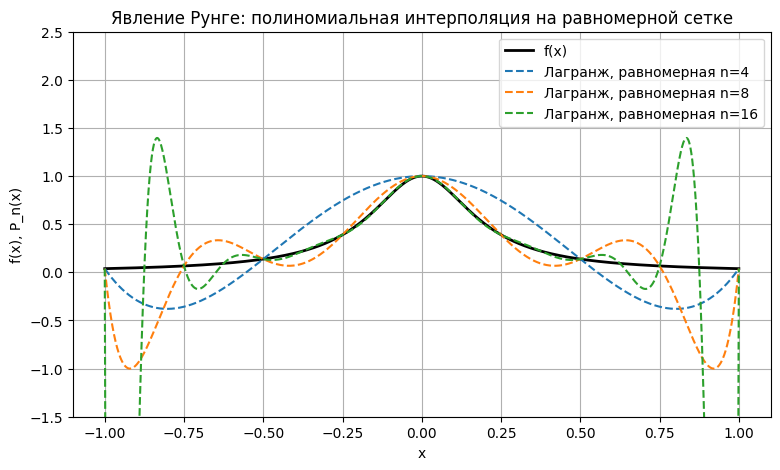

In [7]:
plt.figure(figsize=(9, 5))
plt.plot(x_eval, f_eval, 'k-', lw=2, label='f(x)')
for n in [4, 8, 16]:
    nodes = uniform_grid(n)
    p = lagrange_interp(nodes, f(nodes), x_eval)
    plt.plot(x_eval, p, '--', label=f'Лагранж, равномерная n={n}')
plt.ylim(-1.5, 2.5)
plt.xlabel('x')
plt.ylabel('f(x), P_n(x)')
plt.title('Явление Рунге: полиномиальная интерполяция на равномерной сетке')
plt.grid(True)
plt.legend()
plt.show()

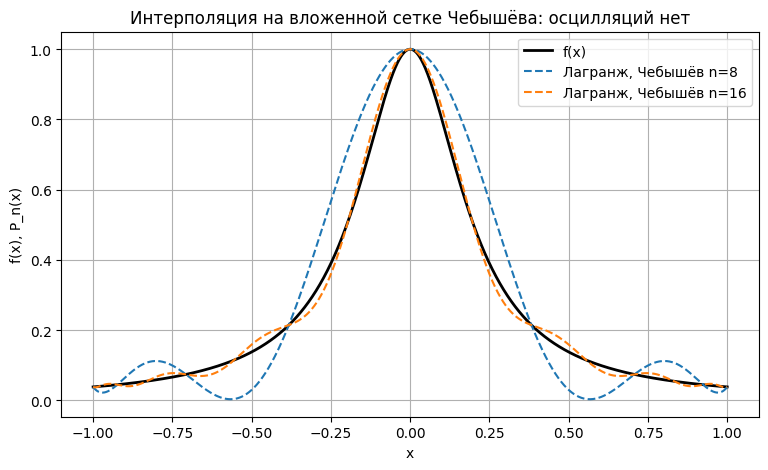

In [8]:
plt.figure(figsize=(9, 5))
plt.plot(x_eval, f_eval, 'k-', lw=2, label='f(x)')
for n in [8, 16]:
    nodes = chebyshev_grid(n)
    p = lagrange_interp(nodes, f(nodes), x_eval)
    plt.plot(x_eval, p, '--', label=f'Лагранж, Чебышёв n={n}')
plt.xlabel('x')
plt.ylabel('f(x), P_n(x)')
plt.title('Интерполяция на вложенной сетке Чебышёва: осцилляций нет')
plt.grid(True)
plt.legend()
plt.show()

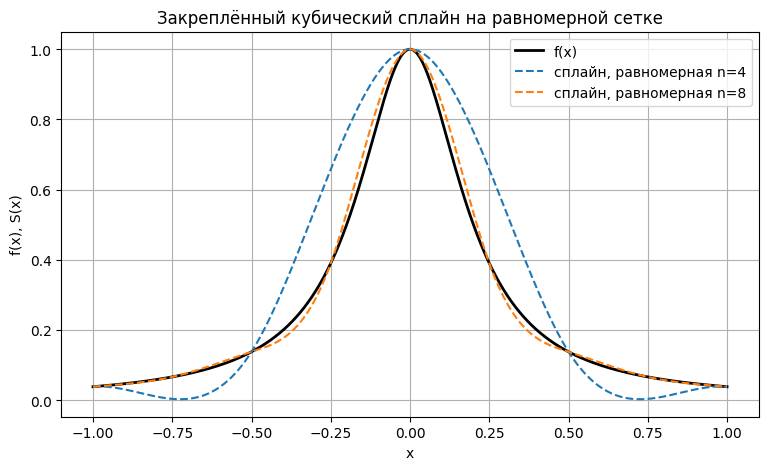

In [9]:
plt.figure(figsize=(9, 5))
plt.plot(x_eval, f_eval, 'k-', lw=2, label='f(x)')
for n in [4, 8]:
    nodes = uniform_grid(n)
    c = clamped_spline_coeffs(nodes, f(nodes), f_prime(-1.0), f_prime(1.0))
    plt.plot(x_eval, spline_eval(nodes, f(nodes), c, x_eval), '--',
             label=f'сплайн, равномерная n={n}')
plt.xlabel('x')
plt.ylabel('f(x), S(x)')
plt.title('Закреплённый кубический сплайн на равномерной сетке')
plt.grid(True)
plt.legend()
plt.show()

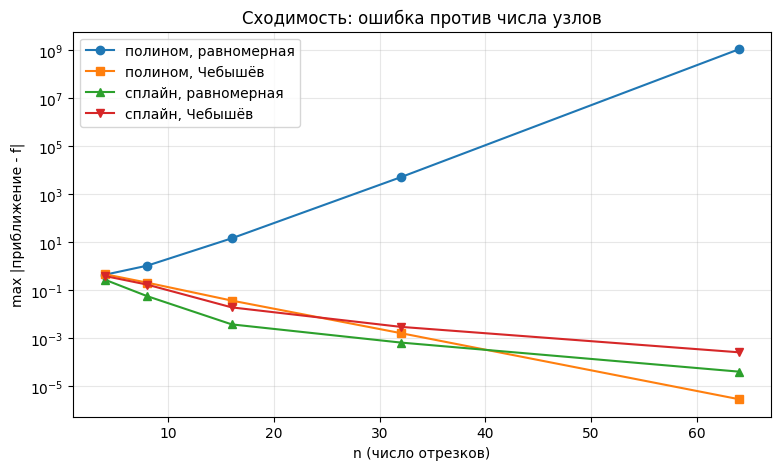

In [10]:
err_lag_u = [r[2] for r in rows if r[0] == 'равномерная']
err_spl_u = [r[4] for r in rows if r[0] == 'равномерная']
err_lag_c = [r[2] for r in rows if r[0] == 'чебышёвская']
err_spl_c = [r[4] for r in rows if r[0] == 'чебышёвская']

plt.figure(figsize=(9, 5))
plt.semilogy(ns, err_lag_u, 'o-', label='полином, равномерная')
plt.semilogy(ns, err_lag_c, 's-', label='полином, Чебышёв')
plt.semilogy(ns, err_spl_u, '^-', label='сплайн, равномерная')
plt.semilogy(ns, err_spl_c, 'v-', label='сплайн, Чебышёв')
plt.xlabel('n (число отрезков)')
plt.ylabel('max |приближение - f|')
plt.title('Сходимость: ошибка против числа узлов')
plt.grid(True, which='both', alpha=0.3)
plt.legend()
plt.show()

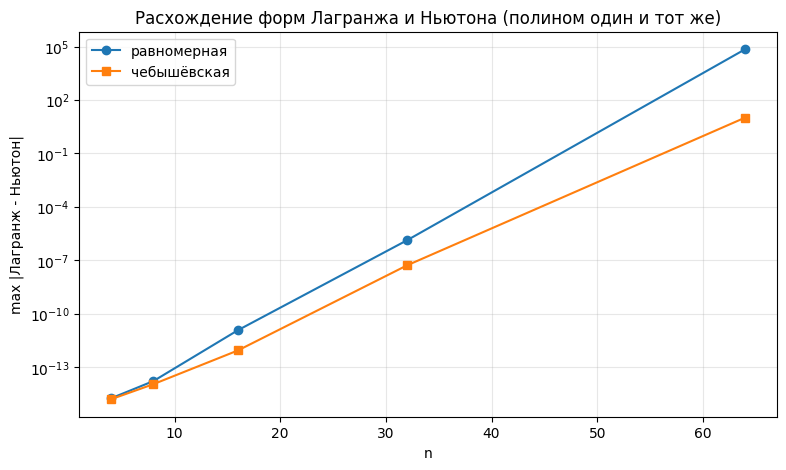

In [11]:
diff_u = [r[5] for r in rows if r[0] == 'равномерная']
diff_c = [r[5] for r in rows if r[0] == 'чебышёвская']

plt.figure(figsize=(9, 5))
plt.semilogy(ns, diff_u, 'o-', label='равномерная')
plt.semilogy(ns, diff_c, 's-', label='чебышёвская')
plt.xlabel('n')
plt.ylabel('max |Лагранж - Ньютон|')
plt.title('Расхождение форм Лагранжа и Ньютона (полином один и тот же)')
plt.grid(True, which='both', alpha=0.3)
plt.legend()
plt.show()

### 8. Что показывают полученные числа

- **Равномерная сетка, полином:** ошибка не убывает, а растёт с $n$ — это явление Рунге.
  Осцилляции концентрируются у краёв $|x|\approx 0.8\text{–}1$; на графике видно, как
  при $n=16$ полином «размахивается» сильнее, чем при $n=8$.
- **Сетка Чебышёва, полином:** ошибка убывает геометрически (порядка $10^{-6}$ и ниже к $n=64$):
  сгущение узлов к краям компенсирует рост производных функции.
- **Сплайн:** сходится на обеих сетках и не страдает явлением Рунге. На равномерной сетке
  ошибка уменьшается примерно в 16 раз при удвоении $n$ (порядок $O(h^4)$); на чебышёвской
  она ещё меньше, потому что узлы сгущены там, где функция круче. Закреплённые условия
  дают полный четвёртый порядок, включая края.
- **Лагранж против Ньютона:** на сетке Чебышёва расхождение на уровне машинного округления
  ($10^{-14}\dots10^{-10}$) — формы дают один полином. На равномерной сетке при $n=64$
  расхождение растёт: это не разница методов, а накопление округлений в плохо обусловленной
  задаче (обе формы численно неустойчивы при больших $n$ на равномерных узлах).

### 9. Вывод

Выбор узлов важнее формы записи полинома: на равномерной сетке интерполяция расходится
(явление Рунге), а на вложенной сетке Чебышёва сходится геометрически. Формы Лагранжа и
Ньютона математически эквивалентны и расходятся лишь на уровне округлений. Кубический
сплайн с закреплёнными граничными условиями устойчив на обеих сетках и даёт ошибку
порядка $O(h^4)$, поэтому для функций с большими производными кусочно-полиномиальная
аппроксимация предпочтительнее полинома высокой степени.